Libraries imported successfully!


Saving Unconfirmed 30567.crdownload to Unconfirmed 30567.crdownload
Saving Unconfirmed 796251.crdownload to Unconfirmed 796251.crdownload
Saving Unconfirmed 376519.crdownload to Unconfirmed 376519.crdownload
Vectors detected: Unconfirmed 30567.crdownload
Annotation file detected: Unconfirmed 796251.crdownload
Annotation file detected: Unconfirmed 376519.crdownload
ECG/SCG annotation roles cannot be verified from filenames; optional ECG comparison skipped.
X-axis: (106590,)
Y-axis: (106590,)
Z-axis: (106590,)
Timestamp: (106590,)
ECG LARA: (106590,)
ECG LLLA: (106590,)
ECG LLRA: (106590,)
ECG VxRL: (106590,)
Median timestamp interval: 3.90625 ms
Sampling frequency: 256.0 Hz
Recording duration: 416.3671875 seconds


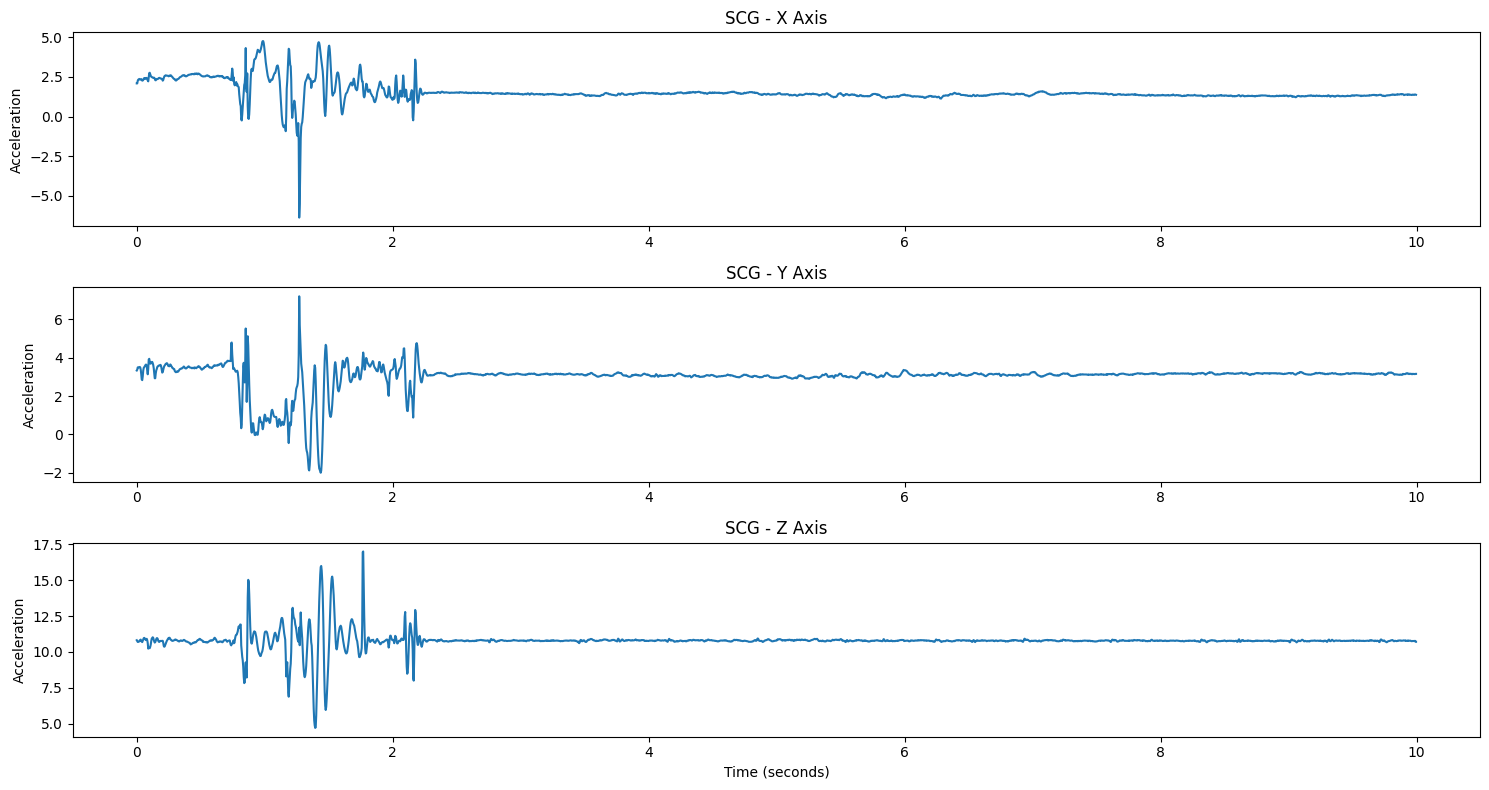

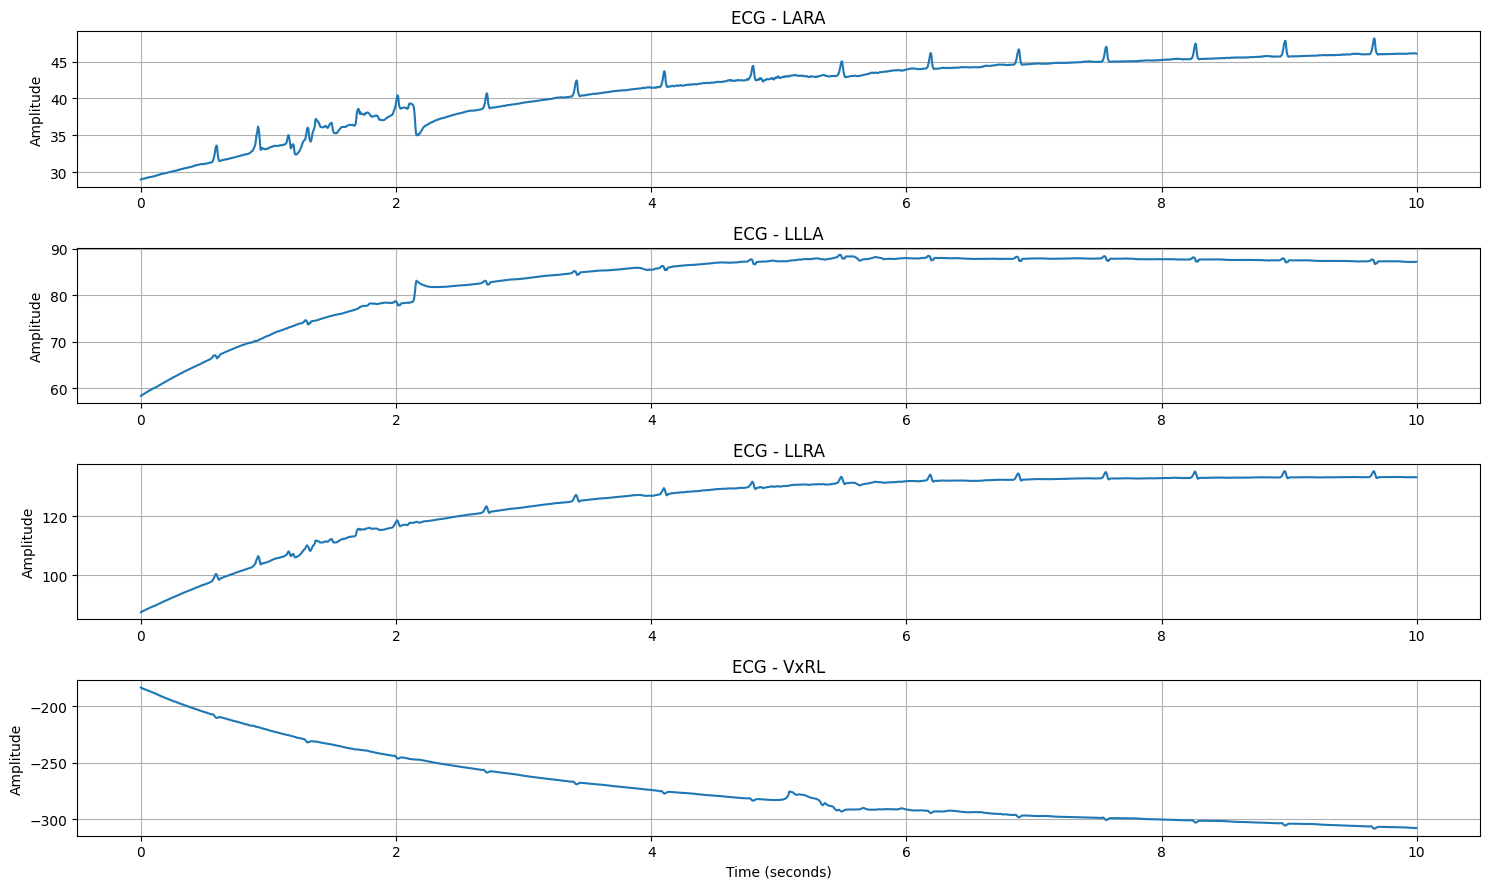

ECG and SCG filtering completed!


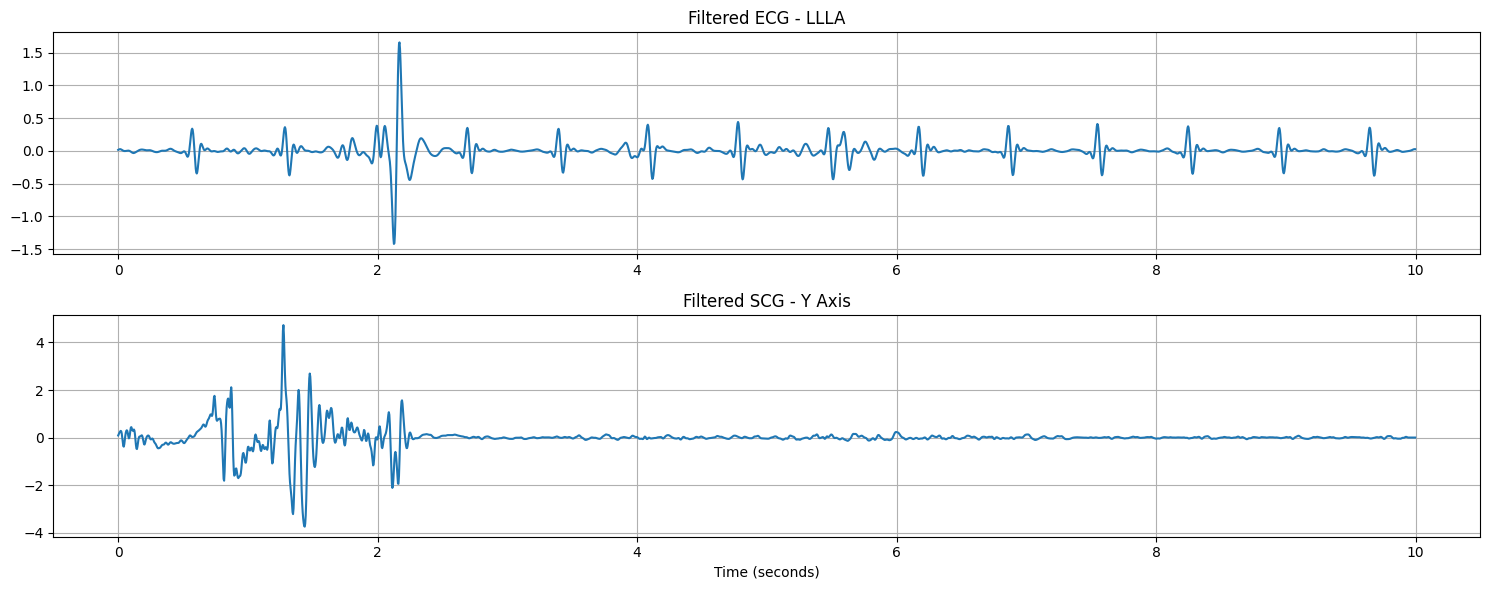

Total R-peaks detected: 592
First 15 R-peak sample positions:
[ 146  329  555  689  869 1045 1223 1432 1579 1756 1932 2111 2291 2469
 2649]

First 15 R-peak times (seconds):
[ 0.57   1.285  2.168  2.691  3.395  4.082  4.777  5.594  6.168  6.859
  7.547  8.246  8.949  9.645 10.348]


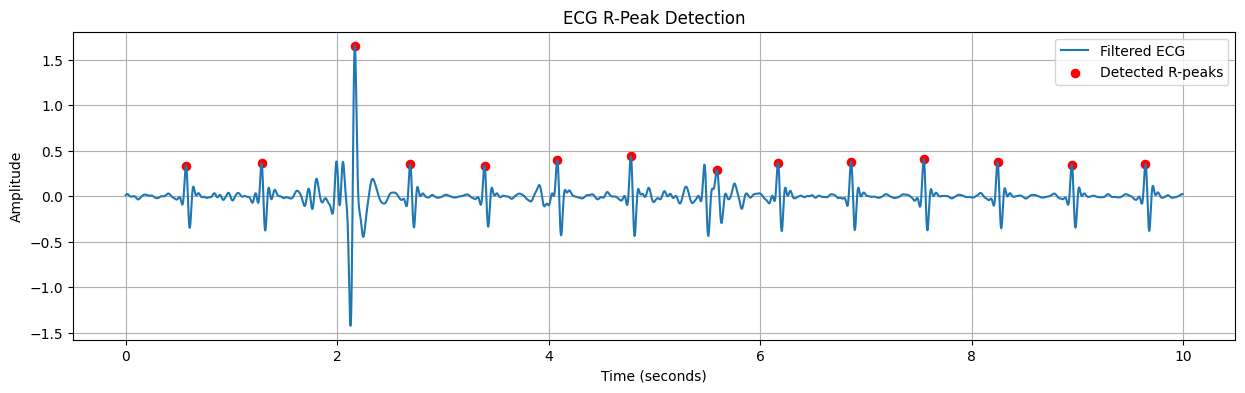

Detected RR median: 703.12 ms
Detected heart rate: 85.33 BPM

SCG segmentation completed!
Valid cardiac cycles: 591
Segment shape: (591, 230)


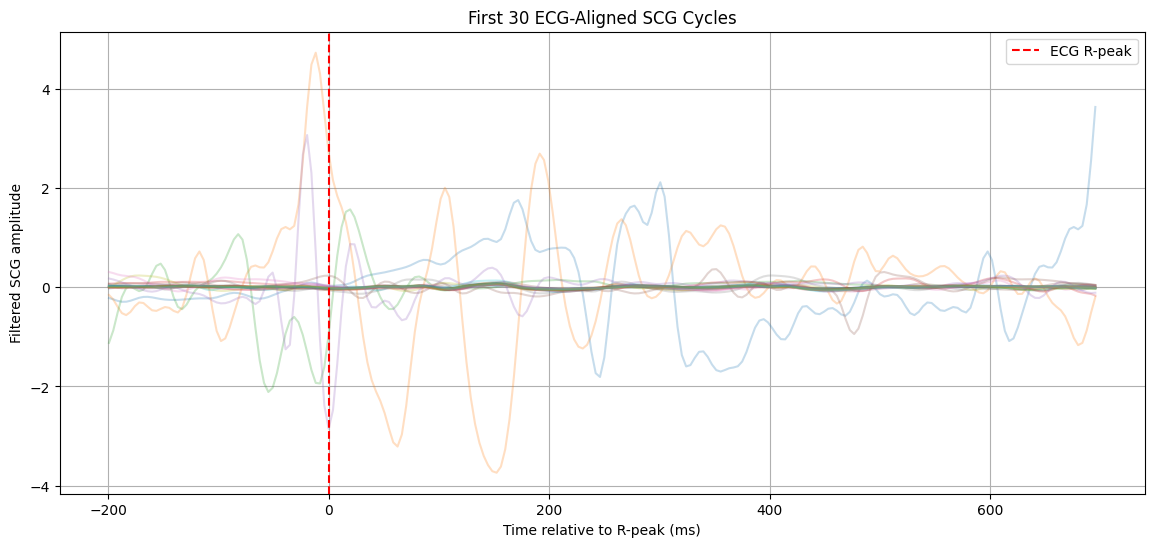

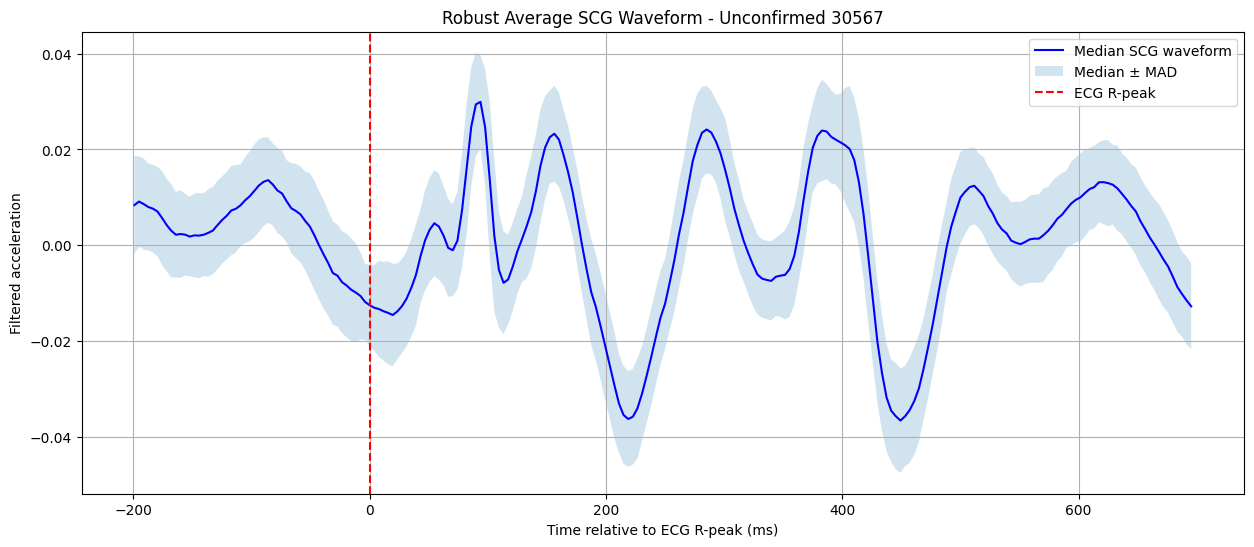

Fiducial detection completed!
Total beats: 591
   Beat  R_peak_sample  R_peak_time_s  Bs_sample  Bs_time_ms  Cs_sample  \
0     1            146       0.570312        110  -140.62500        130   
1     2            329       1.285156        304   -97.65625        324   
2     3            555       2.167969        534   -82.03125        541   
3     4            689       2.691406        664   -97.65625        664   
4     5            869       3.394531        830  -152.34375        864   

   Cs_time_ms  Es_sample  Es_time_ms  Gs_sample  Gs_time_ms  Bd_sample  \
0   -62.50000        162    62.50000        168    85.93750        224   
1   -19.53125        326   -11.71875        345    62.50000        420   
2   -54.68750        553    -7.81250        560    19.53125        651   
3   -97.65625        701    46.87500        715   101.56250        777   
4   -19.53125        866   -11.71875        881    46.87500        963   

   Bd_time_ms  Hd_sample  Hd_time_ms  
0   304.68750     

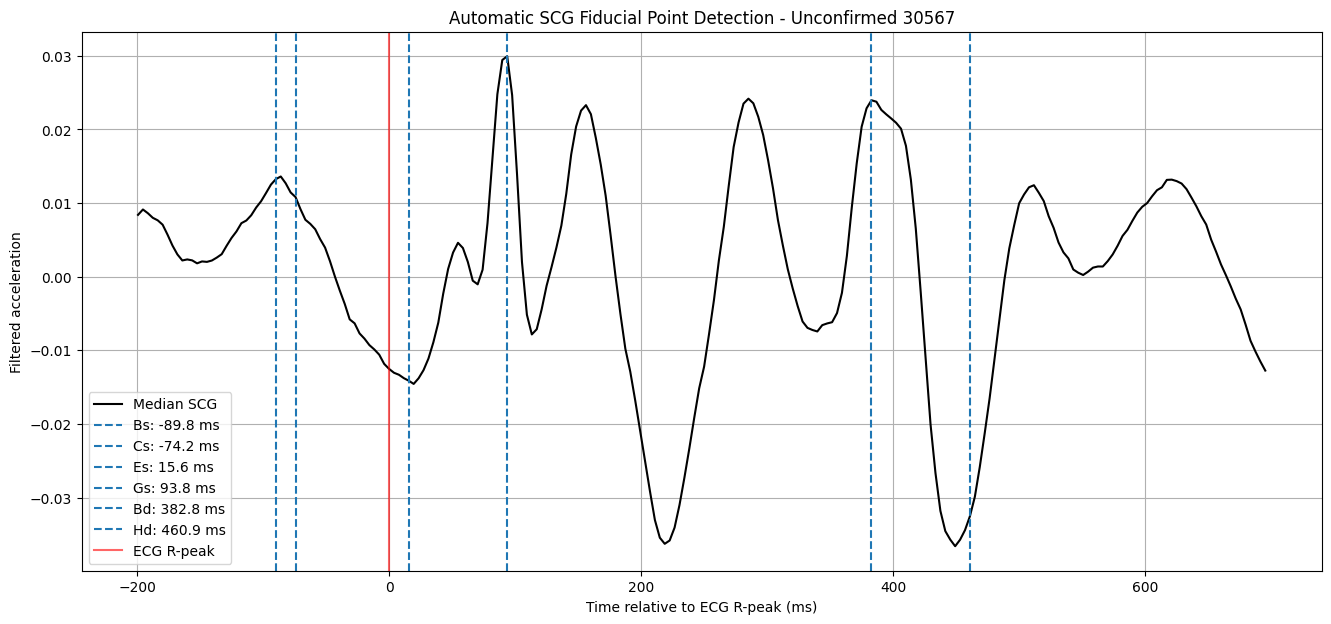

Results exported successfully!


,mean,median,std,min,max
Bs_time_ms,-97.061390,-89.84375,22.972915,-152.34375,-66.40625
Cs_time_ms,-67.562923,-74.21875,27.856860,-105.46875,-19.53125
Es_time_ms,15.135893,15.62500,24.335472,-23.43750,62.50000
Gs_time_ms,83.538230,93.75000,23.452966,15.62500,101.56250
Bd_time_ms,371.979431,382.81250,25.218983,304.68750,390.62500
Hd_time_ms,468.571542,460.93750,17.575378,460.93750,546.87500


HEFA-2018 detection completed!
Total beats: 591

Detected fiducial summary:


,count,mean,median,std,min,max
Bs_time_ms,575.0,-91.277174,-89.84375,22.904929,-156.25000,-46.87500
Cs_time_ms,588.0,-74.550914,-82.03125,22.622417,-113.28125,-11.71875
Es_time_ms,591.0,12.234296,11.71875,23.080406,-35.15625,70.31250
Gs_time_ms,567.0,91.545414,93.75000,5.010949,74.21875,105.46875
Bd_time_ms,532.0,386.344279,382.81250,10.466357,351.56250,410.15625
Hd_time_ms,519.0,452.628251,453.12500,9.349714,437.50000,484.37500


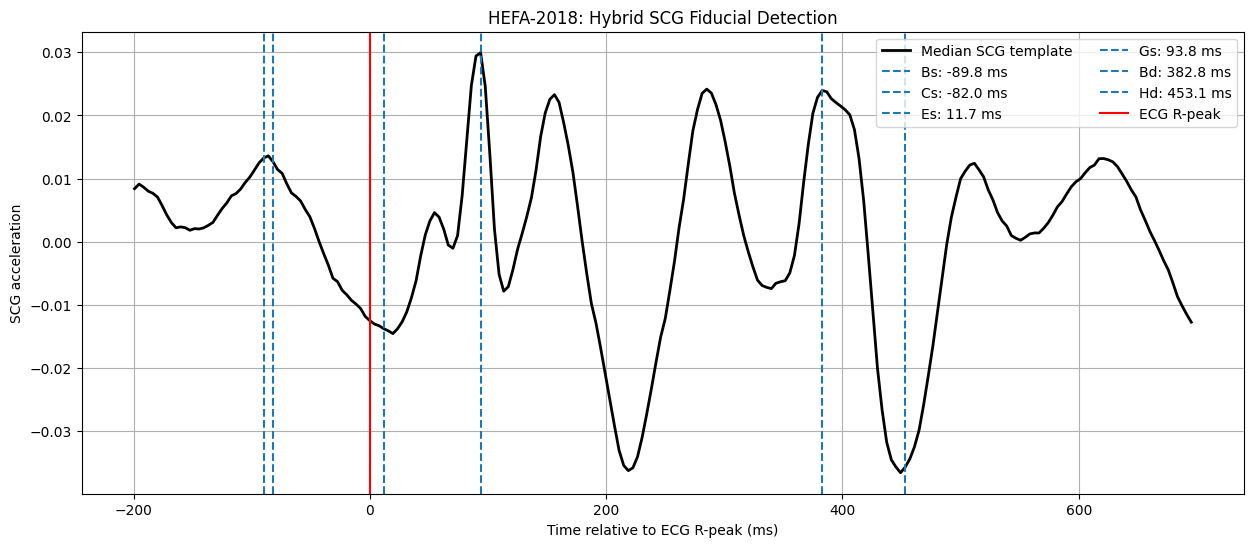

,count,mean,median,std,min,max
Bs_time_ms,575.0,-91.277174,-89.84375,22.904929,-156.25000,-46.87500
Cs_time_ms,588.0,-74.550914,-82.03125,22.622417,-113.28125,-11.71875
Es_time_ms,591.0,12.234296,11.71875,23.080406,-35.15625,70.31250
Gs_time_ms,567.0,91.545414,93.75000,5.010949,74.21875,105.46875
Bd_time_ms,532.0,386.344279,382.81250,10.466357,351.56250,410.15625
Hd_time_ms,519.0,452.628251,453.12500,9.349714,437.50000,484.37500


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
!pip install -q numpy pandas scipy matplotlib neurokit2


import numpy as np
import pandas as pd
import scipy.io as sio
import matplotlib.pyplot as plt
import neurokit2 as nk

from scipy.signal import butter, filtfilt, find_peaks
from scipy.stats import median_abs_deviation

print("Libraries imported successfully!")

from google.colab import files
from io import BytesIO
from pathlib import Path
import zipfile
from IPython.display import display

uploaded = files.upload()
if not uploaded:
    raise ValueError("Please upload your MATLAB files.")
loaded = {}
for name, content in uploaded.items():
    try:
        loaded[name] = sio.loadmat(BytesIO(content), squeeze_me=True, struct_as_record=False)
    except Exception as exc:
        print(f"Skipping {name}: {exc}")
required = ["Shimmer_D0CD_Accel_LN_X_CAL1", "Shimmer_D0CD_Accel_LN_Y_CAL1", "Shimmer_D0CD_Accel_LN_Z_CAL1", "Shimmer_D0CD_Timestamp_Shimmer_CAL1"] + [f"Shimmer_D0CD_ECG_{ch}_24BIT_CAL1" for ch in ("LARA", "LLLA", "LLRA", "VxRL")]
matches = [(name, data) for name, data in loaded.items() if all(k in data for k in required)]
if len(matches) != 1:
    raise ValueError("Upload exactly one compatible Vectors file per run.")
vector_name, vec_mat = matches[0]
prefix = Path(vector_name).stem.removesuffix("-Vectors")
print("Vectors detected:", vector_name)
# Both unnamed annotation files have the same structure; do not guess their roles.
annotations = [(name,d['data']) for name,d in loaded.items() if hasattr(d.get('data'), 'RR_int')]
for name, annotation in annotations:
    print('Annotation file detected:', name)
ecg_mat = next((d for name,d in loaded.items() if Path(name).stem.lower().endswith('-ecg') and 'data' in d), None)
if ecg_mat is None:
    print('ECG/SCG annotation roles cannot be verified from filenames; optional ECG comparison skipped.')

# Extract acceleration signals
x = np.asarray(
    vec_mat["Shimmer_D0CD_Accel_LN_X_CAL1"]
).flatten().astype(float)

y = np.asarray(
    vec_mat["Shimmer_D0CD_Accel_LN_Y_CAL1"]
).flatten().astype(float)

z = np.asarray(
    vec_mat["Shimmer_D0CD_Accel_LN_Z_CAL1"]
).flatten().astype(float)

# Extract timestamps
timestamp = np.asarray(
    vec_mat["Shimmer_D0CD_Timestamp_Shimmer_CAL1"]
).flatten().astype(float)

# Extract all ECG channels
ecg_channels = {
    "LARA": np.asarray(vec_mat["Shimmer_D0CD_ECG_LARA_24BIT_CAL1"]).flatten().astype(float),
    "LLLA": np.asarray(vec_mat["Shimmer_D0CD_ECG_LLLA_24BIT_CAL1"]).flatten().astype(float),
    "LLRA": np.asarray(vec_mat["Shimmer_D0CD_ECG_LLRA_24BIT_CAL1"]).flatten().astype(float),
    "VxRL": np.asarray(vec_mat["Shimmer_D0CD_ECG_VxRL_24BIT_CAL1"]).flatten().astype(float)
}

print("X-axis:", x.shape)
print("Y-axis:", y.shape)
print("Z-axis:", z.shape)
print("Timestamp:", timestamp.shape)

for name, signal in ecg_channels.items():
    print(f"ECG {name}: {signal.shape}")


#Calculate sampling frequency

dt = np.median(np.diff(timestamp))

fs = 1000 / dt

print("Median timestamp interval:", dt, "ms")
print("Sampling frequency:", fs, "Hz")
print("Recording duration:", len(timestamp) / fs, "seconds")

if not np.isfinite(fs) or fs <= 180:
    raise ValueError("Sampling rate must exceed 180 Hz for the original HEFA filter.")
if any(len(a) != len(timestamp) for a in [x,y,z,*ecg_channels.values()]):
    raise ValueError("Signal lengths do not match timestamps.")



duration = 10
n = min(len(timestamp), int(duration * fs))
time = np.arange(n) / fs

# Plot three SCG axes
plt.figure(figsize=(15, 8))

plt.subplot(3, 1, 1)
plt.plot(time, x[:n])
plt.title("SCG - X Axis")
plt.ylabel("Acceleration")

plt.subplot(3, 1, 2)
plt.plot(time, y[:n])
plt.title("SCG - Y Axis")
plt.ylabel("Acceleration")

plt.subplot(3, 1, 3)
plt.plot(time, z[:n])
plt.title("SCG - Z Axis")
plt.ylabel("Acceleration")

plt.xlabel("Time (seconds)")
plt.tight_layout()
plt.show()


# Plot all ECG channels
plt.figure(figsize=(15, 9))

for i, (name, signal) in enumerate(ecg_channels.items(), 1):
    plt.subplot(4, 1, i)
    plt.plot(time, signal[:n])
    plt.title("ECG - " + name)
    plt.ylabel("Amplitude")
    plt.grid()

plt.xlabel("Time (seconds)")
plt.tight_layout()
plt.show()



# Select channels
ecg_raw = ecg_channels["LLLA"]
scg_raw = y.copy()

# Butterworth bandpass filter
def bandpass_filter(signal, low, high, fs, order=4):
    nyquist = fs / 2
    b, a = butter(
        order,
        [low / nyquist, high / nyquist],
        btype="band"
    )
    return filtfilt(b, a, signal)

# Filter ECG and SCG
ecg_filtered = bandpass_filter(ecg_raw, 5, 20, fs)
scg_filtered = bandpass_filter(scg_raw, 1, 40, fs)

print("ECG and SCG filtering completed!")



duration = 10
n = min(len(timestamp), int(duration * fs))
time = np.arange(n) / fs

plt.figure(figsize=(15, 6))

plt.subplot(2, 1, 1)
plt.plot(time, ecg_filtered[:n])
plt.title("Filtered ECG - LLLA")
plt.grid()

plt.subplot(2, 1, 2)
plt.plot(time, scg_filtered[:n])
plt.title("Filtered SCG - Y Axis")
plt.xlabel("Time (seconds)")
plt.grid()

plt.tight_layout()
plt.show()


# Detect ECG R-peaks
_, rpeaks_info = nk.ecg_peaks(
    ecg_filtered,
    sampling_rate=round(fs)
)

rpeaks = rpeaks_info["ECG_R_Peaks"]

print("Total R-peaks detected:", len(rpeaks))
print("First 15 R-peak sample positions:")
print(rpeaks[:15])

print("\nFirst 15 R-peak times (seconds):")
print(np.round(rpeaks[:15] / fs, 3))


if len(rpeaks) < 2:
    raise ValueError("Insufficient detected peaks for analysis.")


#Visualize detected R-peaks


plt.figure(figsize=(15, 4))

plt.plot(time, ecg_filtered[:n], label="Filtered ECG")

valid = rpeaks[rpeaks < n]

plt.scatter(
    valid / fs,
    ecg_filtered[valid],
    color="red",
    s=35,
    label="Detected R-peaks"
)

plt.title("ECG R-Peak Detection")
plt.xlabel("Time (seconds)")
plt.ylabel("Amplitude")
plt.legend()
plt.grid()
plt.show()


if ecg_mat is not None:
    try:
        RR_int = np.asarray(ecg_mat["data"].RR_int).squeeze()
        print("Provided RR median (first annotation array):", np.median(RR_int[0]))
    except Exception as exc:
        print("Annotation comparison unavailable:", exc)


#Validate R-peaks and segment SCG cycles


# Calculate RR intervals from detected ECG peaks
detected_rr = np.diff(rpeaks) / fs * 1000

print("Detected RR median:", round(np.median(detected_rr), 2), "ms")

print("Detected heart rate:", round(60000 / np.median(detected_rr), 2), "BPM")

# Segment SCG around every ECG R-peak
pre_samples = int(0.200 * fs)
post_samples = int(0.700 * fs)

segments = []
valid_rpeaks = []

for r in rpeaks:
    start = r - pre_samples
    end = r + post_samples

    if start >= 0 and end < len(scg_filtered):
        segment = scg_filtered[start:end]

        segments.append(segment)
        valid_rpeaks.append(r)

segments = np.asarray(segments)
valid_rpeaks = np.asarray(valid_rpeaks)

print("\nSCG segmentation completed!")
print("Valid cardiac cycles:", len(segments))
print("Segment shape:", segments.shape)


if len(segments) == 0:
    raise ValueError("No complete SCG cycles found.")



relative_time = (
    np.arange(segments.shape[1]) - pre_samples
) / fs * 1000

plt.figure(figsize=(14, 6))

for i in range(min(30, len(segments))):
    plt.plot(relative_time, segments[i], alpha=0.25)

plt.axvline(0, color="red", linestyle="--", label="ECG R-peak")
plt.title("First 30 ECG-Aligned SCG Cycles")
plt.xlabel("Time relative to R-peak (ms)")
plt.ylabel("Filtered SCG amplitude")
plt.legend()
plt.grid()
plt.show()

#Generate a robust average SCG waveform


# Robust average SCG template
average_scg = np.median(segments, axis=0)

# Calculate variability at each time point
scg_mad = median_abs_deviation(
    segments,
    axis=0,
    scale="normal"
)

plt.figure(figsize=(15, 6))

plt.plot(
    relative_time,
    average_scg,
    color="blue",
    label="Median SCG waveform"
)

plt.fill_between(
    relative_time,
    average_scg - scg_mad,
    average_scg + scg_mad,
    alpha=0.2,
    label="Median ± MAD"
)

plt.axvline(0, color="red", linestyle="--", label="ECG R-peak")

plt.title(f"Robust Average SCG Waveform - {prefix}")
plt.xlabel("Time relative to ECG R-peak (ms)")
plt.ylabel("Filtered acceleration")
plt.legend()
plt.grid()
plt.show()


#Automatic SCG fiducial detection


from scipy.signal import find_peaks

# Reference timings from the 2018 paper (milliseconds after ECG R-peak)
fiducial_reference = {
    "Bs": -111,
    "Cs": -61,
    "Es": 19,
    "Gs": 59,
    "Bd": 348,
    "Hd": 505
}

# Search window around each reference
window_ms = 45

fiducial_results = []

for beat_idx, (segment, r) in enumerate(zip(segments, valid_rpeaks)):

    row = {
        "Beat": beat_idx + 1,
        "R_peak_sample": int(r),
        "R_peak_time_s": r / fs
    }

    for point, reference in fiducial_reference.items():

        left = reference - window_ms
        right = reference + window_ms

        mask = (
            (relative_time >= left) &
            (relative_time <= right)
        )

        indices = np.where(mask)[0]

        if len(indices) == 0:
            row[point + "_sample"] = np.nan
            row[point + "_time_ms"] = np.nan
            continue

        values = segment[indices]

        # Select the strongest local extremum in the search window
        local_max = np.argmax(values)
        local_min = np.argmin(values)

        if abs(values[local_max]) >= abs(values[local_min]):
            selected_idx = indices[local_max]
        else:
            selected_idx = indices[local_min]

        offset_ms = relative_time[selected_idx]
        absolute_sample = int(r + selected_idx - pre_samples)

        row[point + "_sample"] = absolute_sample
        row[point + "_time_ms"] = offset_ms

    fiducial_results.append(row)

fiducial_df = pd.DataFrame(fiducial_results)

print("Fiducial detection completed!")
print("Total beats:", len(fiducial_df))
print(fiducial_df.head())


#Plot all six detected points


plt.figure(figsize=(16, 7))

plt.plot(relative_time, average_scg, color="black", label="Median SCG")

for point in fiducial_reference:

    col = point + "_time_ms"
    detected_time = fiducial_df[col].median()

    plt.axvline(
        detected_time,
        linestyle="--",
        label=f"{point}: {detected_time:.1f} ms"
    )

plt.axvline(0, color="red", alpha=0.6, label="ECG R-peak")

plt.title(f"Automatic SCG Fiducial Point Detection - {prefix}")
plt.xlabel("Time relative to ECG R-peak (ms)")
plt.ylabel("Filtered acceleration")
plt.legend()
plt.grid()
plt.show()



# Beat-level results
fiducial_df.to_csv(
    f"{prefix}_Fiducial_Detections.csv",
    index=False
)

# Summary statistics
summary = fiducial_df.filter(regex="_time_ms$").agg(
    ["mean", "median", "std", "min", "max"]
).T

summary.to_csv(f"{prefix}_Fiducial_Summary.csv")

print("Results exported successfully!")
display(summary)



import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from scipy.signal import butter, filtfilt, find_peaks
from scipy.ndimage import uniform_filter1d

# ==========================================================
# HEFA-2018: HYBRID FIDUCIAL DETECTION
# ==========================================================

# 1. Build a high-frequency acceleration envelope
def highpass(signal, low=25, high=90, fs=256, order=3):
    nyq = fs / 2
    b, a = butter(
        order,
        [low / nyq, high / nyq],
        btype="band"
    )
    return filtfilt(b, a, signal)

# Process all three axes
hx = highpass(x, fs=fs)
hy = highpass(y, fs=fs)
hz = highpass(z, fs=fs)

# Combined high-frequency acceleration
hfacc = np.sqrt(hx**2 + hy**2 + hz**2)

# Smoothed RMS envelope
window = max(3, int(0.040 * fs))
hf_envelope = np.sqrt(
    uniform_filter1d(hfacc**2, size=window)
)

# 2. Reference windows in milliseconds after ECG R-peak
# These are initial search centres, not ground-truth timings.
references = {
    "Bs": -111,
    "Cs": -61,
    "Es": 16,
    "Gs": 59,
    "Bd": 348,
    "Hd": 505
}

search_width = {
    "Bs": 65,
    "Cs": 55,
    "Es": 55,
    "Gs": 55,
    "Bd": 65,
    "Hd": 75
}

# 3. Calculate a robust morphology template
template = np.median(segments, axis=0)

# 4. Candidate-based detection with envelope guidance
results = []

for beat_i, (seg, r) in enumerate(
    zip(segments, valid_rpeaks)
):

    row = {
        "Beat": beat_i + 1,
        "R_peak_sample": int(r),
        "R_peak_time_s": r / fs
    }

    # Extract corresponding HFACC envelope segment
    start = int(r - pre_samples)
    end = start + len(seg)

    env = hf_envelope[start:end]

    for point, ref in references.items():

        width = search_width[point]

        mask = (
            (relative_time >= ref - width) &
            (relative_time <= ref + width)
        )

        idx = np.where(mask)[0]

        if len(idx) < 5:
            row[point + "_sample"] = np.nan
            row[point + "_time_ms"] = np.nan
            row[point + "_confidence"] = 0.0
            continue

        signal_part = seg[idx]
        envelope_part = env[idx]

        # Determine expected polarity from the median template
        template_part = template[idx]
        expected_sign = (
            1 if np.max(template_part) >= abs(np.min(template_part))
            else -1
        )

        # Find both positive and negative local extrema
        peaks, _ = find_peaks(
            expected_sign * signal_part,
            prominence=max(
                np.std(signal_part) * 0.15, 1e-8
            ),
            distance=max(1, int(0.015 * fs))
        )

        # Include a fallback candidate if no local peak exists
        if len(peaks) == 0:
            peaks = np.array([
                np.argmax(expected_sign * signal_part)
            ])

        # Score each candidate using:
        # morphology prominence + HFACC envelope + template agreement
        scores = []

        for p in peaks:
            absolute_idx = idx[p]

            prominence = abs(signal_part[p])
            envelope_score = envelope_part[p]

            morphology_score = abs(
                seg[absolute_idx] - template[absolute_idx]
            )

            # Lower mismatch to template is better
            score = (
                0.55 * prominence /
                (np.max(np.abs(signal_part)) + 1e-8)
                +
                0.30 * envelope_score /
                (np.max(envelope_part) + 1e-8)
                +
                0.15 * (
                    1 - min(
                        morphology_score /
                        (np.std(segments[:, absolute_idx]) + 1e-8),
                        1
                    )
                )
            )

            scores.append(score)

        best = int(np.argmax(scores))
        selected = idx[peaks[best]]

        # Confidence is a relative candidate score
        confidence = float(scores[best])

        row[point + "_sample"] = int(r + selected - pre_samples)
        row[point + "_time_ms"] = float(relative_time[selected])
        row[point + "_confidence"] = confidence

    results.append(row)

hefa_df = pd.DataFrame(results)

# 5. Reject extreme beat-level timing outliers
for point in references:
    col = point + "_time_ms"

    med = hefa_df[col].median()
    mad = np.median(np.abs(hefa_df[col] - med))

    if mad > 0:
        outlier = np.abs(hefa_df[col] - med) > 3 * 1.4826 * mad
        hefa_df.loc[outlier, col] = np.nan
        hefa_df.loc[outlier, point + "_sample"] = np.nan

print("HEFA-2018 detection completed!")
print("Total beats:", len(hefa_df))
print("\nDetected fiducial summary:")
display(
    hefa_df.filter(regex="_time_ms$").agg(
        ["count", "mean", "median", "std", "min", "max"]
    ).T
)


#New Detections


plt.figure(figsize=(15, 6))

plt.plot(
    relative_time,
    template,
    color="black",
    linewidth=2,
    label="Median SCG template"
)

for point in references:
    detected = hefa_df[point + "_time_ms"].median()

    if np.isfinite(detected):
        plt.axvline(
            detected,
            linestyle="--",
            label=f"{point}: {detected:.1f} ms"
        )

plt.axvline(0, color="red", label="ECG R-peak")

plt.title("HEFA-2018: Hybrid SCG Fiducial Detection")
plt.xlabel("Time relative to ECG R-peak (ms)")
plt.ylabel("SCG acceleration")
plt.legend(ncol=2)
plt.grid()
plt.show()


#Export the new results

hefa_df.to_csv(
    f"{prefix}_HEFA2018_Detections.csv",
    index=False
)

hefa_summary = hefa_df.filter(
    regex="_time_ms$"
).agg(["count", "mean", "median", "std", "min", "max"]).T

hefa_summary.to_csv(
    f"{prefix}_HEFA2018_Summary.csv"
)



display(hefa_summary)
outputs = [f"{prefix}_{suffix}.csv" for suffix in ("Fiducial_Detections", "Fiducial_Summary", "HEFA2018_Detections", "HEFA2018_Summary")]
zip_name = f"{prefix}_Results.zip"
with zipfile.ZipFile(zip_name, "w", zipfile.ZIP_DEFLATED) as archive:
    for filename in outputs:
        archive.write(filename)
files.download(zip_name)
